# Fraud Detection with a PyOD AutoEncoder

This notebook trains an unsupervised AutoEncoder on legitimate transactions from the anonymized Kaggle credit card dataset. Large reconstruction errors indicate unusual transactions.

Dataset: [Kaggle Fraud Detection](https://www.kaggle.com/datasets/whenamancodes/fraud-detection). Download and extract creditcard.csv into this folder. The target column is Class (0 = legitimate, 1 = fraud). Labels are reserved for splitting and evaluation; only legitimate rows train the model.

## 1. Setup

Install packages from requirements.txt in your Python environment before running this notebook.

In [2]:
!pip install pyod

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 936.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 3.8 MB/s eta 0:00:00


In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path('creditcard.csv')
TARGET = 'Class'
if not DATA_PATH.exists():
    raise FileNotFoundError('Place creditcard.csv beside this notebook.')

## 2. Load and inspect data

Validate the label and use numeric columns as model inputs. The fraud label is excluded from the features.

In [6]:
df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(f'Expected target column: {TARGET}')
df = df.dropna(subset=[TARGET]).copy()
y = df[TARGET].astype(int)
if not set(y.unique()).issubset({0, 1}):
    raise ValueError('Class must contain only 0 and 1.')
X = df.drop(columns=[TARGET]).select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan)
if X.empty:
    raise ValueError('No numeric feature columns found.')
print(f'Rows: {len(df):,} | Numeric features: {X.shape[1]}')
display(y.value_counts().rename(index={0: 'legitimate', 1: 'fraud'}))
display(df.head())

Rows: 91,199 | Numeric features: 30


,count
Class,
legitimate,90988
fraud,211


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


## 3. Split and preprocess

The stratified test split preserves the rare fraud rate. A second split holds back only legitimate rows for threshold calibration. Missing values and scaling are handled using fit data statistics only.

In [7]:
X_train_all, X_test, y_train_all, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
normal_train = X_train_all.loc[y_train_all == 0]
X_fit, X_calibration = train_test_split(normal_train, test_size=0.20, random_state=RANDOM_STATE)
medians = X_fit.median()
X_fit = X_fit.fillna(medians)
X_calibration = X_calibration.fillna(medians)
X_test = X_test.fillna(medians)
scaler = StandardScaler()
X_fit_scaled = scaler.fit_transform(X_fit).astype(np.float32)
X_calibration_scaled = scaler.transform(X_calibration).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)
print(f'Fit rows (legitimate): {len(X_fit):,}')
print(f'Calibration rows (legitimate): {len(X_calibration):,}')
print(f'Test rows: {len(X_test):,} | fraud rows: {int(y_test.sum()):,}')

Fit rows (legitimate): 50,952
Calibration rows (legitimate): 12,739
Test rows: 27,360 | fraud rows: 63


## 4. Train the AutoEncoder

The encoder compresses each transaction into a smaller representation; the decoder attempts to reconstruct the original features. PyOD scores are higher for transactions with greater reconstruction error. Features have already been standardized, so PyOD preprocessing is disabled.

In [8]:
detector = AutoEncoder(
    hidden_neuron_list=[64, 32],
    epoch_num=20,
    batch_size=256,
    contamination=0.01,  # PyOD's internal label threshold; external threshold is calibrated below.
    preprocessing=False,
    random_state=RANDOM_STATE,
    verbose=1,
)
detector.fit(X_fit_scaled)

Training: 100%|██████████| 20/20 [00:14<00:00,  1.34it/s]


AutoEncoder(batch_norm=True, batch_size=256, compile_mode='default',
      contamination=0.01, device=device(type='cpu'), dropout_rate=0.2,
      epoch_num=20, hidden_activation_name='relu',
      hidden_neuron_list=[64, 32], lr=0.001, optimizer_name='adam',
      optimizer_params={'weight_decay': 1e-05}, preprocessing=False,
      random_state=42, use_compile=False, verbose=1)

## 5. Calibrate an alert threshold

The 99.5th percentile of scores from legitimate calibration rows targets an approximate 0.5% false-positive rate on normal transactions under similar conditions. It is a configurable operating point, not a guarantee for future data.

In [9]:
TARGET_FALSE_POSITIVE_RATE = 0.005
calibration_scores = detector.decision_function(X_calibration_scaled)
test_scores = detector.decision_function(X_test_scaled)
threshold = np.quantile(calibration_scores, 1 - TARGET_FALSE_POSITIVE_RATE)
test_predictions = (test_scores >= threshold).astype(int)
print(f'Calibration threshold: {threshold:.6f}')
print(f'Test alerts: {int(test_predictions.sum()):,} / {len(test_predictions):,}')

Calibration threshold: 6.986775
Test alerts: 189 / 27,360


## 6. Evaluate on held-out data

Fraud is rare, so accuracy alone is misleading. ROC-AUC and average precision summarize ranking quality; precision, recall, and the confusion matrix describe this threshold's performance.

In [10]:
print(f'ROC-AUC: {roc_auc_score(y_test, test_scores):.4f}')
print(f'Average precision: {average_precision_score(y_test, test_scores):.4f}')
display(pd.DataFrame(confusion_matrix(y_test, test_predictions), index=['actual legitimate', 'actual fraud'], columns=['predicted legitimate', 'predicted fraud']))
print(classification_report(y_test, test_predictions, target_names=['legitimate', 'fraud'], zero_division=0))

ROC-AUC: 0.9536
Average precision: 0.6383


,predicted legitimate,predicted fraud
actual legitimate,27163,134
actual fraud,8,55


              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00     27297
       fraud       0.29      0.87      0.44        63

    accuracy                           0.99     27360
   macro avg       0.65      0.93      0.72     27360
weighted avg       1.00      0.99      1.00     27360



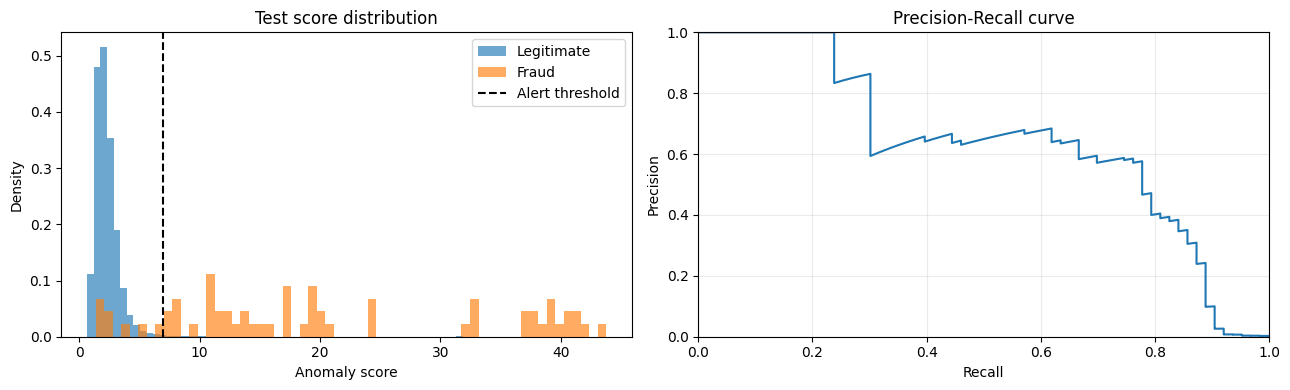

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for class_value, label in [(0, 'Legitimate'), (1, 'Fraud')]:
    axes[0].hist(test_scores[y_test.to_numpy() == class_value], bins=60, alpha=0.65, density=True, label=label)
axes[0].axvline(threshold, color='black', linestyle='--', label='Alert threshold')
axes[0].set(title='Test score distribution', xlabel='Anomaly score', ylabel='Density')
axes[0].legend()
precision, recall, _ = precision_recall_curve(y_test, test_scores)
axes[1].plot(recall, precision)
axes[1].set(title='Precision-Recall curve', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1))
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Interpretation and limitations

- Large scores indicate transactions that the model reconstructs poorly; they are candidates for review, not proof of fraud.
- Review the alert count alongside precision and recall when selecting an operational threshold.
- Recalibrate when the acceptable alert volume or transaction population changes.
- This anonymized historical dataset does not establish production performance or account for changing fraud patterns.